# CO2 geological storage: gas saturation (application)

**Source:** Wen et al. 2022, *U-FNO — an enhanced Fourier neural operator-based deep-learning model for multiphase flow*,
Advances in Water Resources 163:104180 (data and code: github.com/gegewen/ufno). Radial (r, z) reservoir models of CO2
injection through one well, simulated with ECLIPSE; 4500 train / 500 val / 500 test.

**Input** `(96, 200, 24, 12)` per sample: channels `[kr, kz, porosity, injection location, injection rate, pressure,
temperature, Swi, lambda, grid_r, grid_z, grid_t]`; only the time channel varies over the 24 snapshots, so the loader
keeps the 11 static channels at t=0. **Output** `(96, 200, 24)`: gas saturation over 24 log-spaced times (1 day to 30 years).
Reservoirs differ in thickness: cells below the reservoir are zero-padded, and channel 0 (kr) is the active-cell mask.

Loader: `sgpo.data.benchmarks.co2_sg`, `load_split("co2_sg", 4500, 500, 500)`.

In [1]:
import sys; sys.path.insert(0, "..")
import math, numpy as np, torch, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
rel = lambda p, t: ((p - t).flatten(1).norm(dim=1) / t.flatten(1).norm(dim=1))
from sgpo.data.benchmarks import load_split
(xtr, ytr), (xva, yva), (xte, yte) = load_split("co2_sg", 4500, 500, 500)
NAMES = ["kr", "kz", "porosity", "inj_loc", "inj_rate", "pressure", "temperature", "Swi", "lambda", "grid_r", "grid_z"]
act = lambda x: (x[..., 0] != 0)
pd.DataFrame({n: {"min": float(xtr[..., i].min()), "max": float(xtr[..., i].max()), "per-sample constant": bool((xtr[:50, ..., i].flatten(1).std(1) == 0).all())}
              for i, n in enumerate(NAMES)}).T

,min,max,per-sample constant
kr,-0.435353,0.613448,False
kz,-0.744979,0.546368,False
porosity,0.0,0.278479,False
inj_loc,0.0,1.0,False
inj_rate,-0.001656,0.978704,True
pressure,0.012243,0.929757,True
temperature,0.00097,0.999509,True
Swi,0.000245,0.999519,True
lambda,0.000902,0.999898,True
grid_r,0.000038,1.0,False


## Reservoirs and plumes

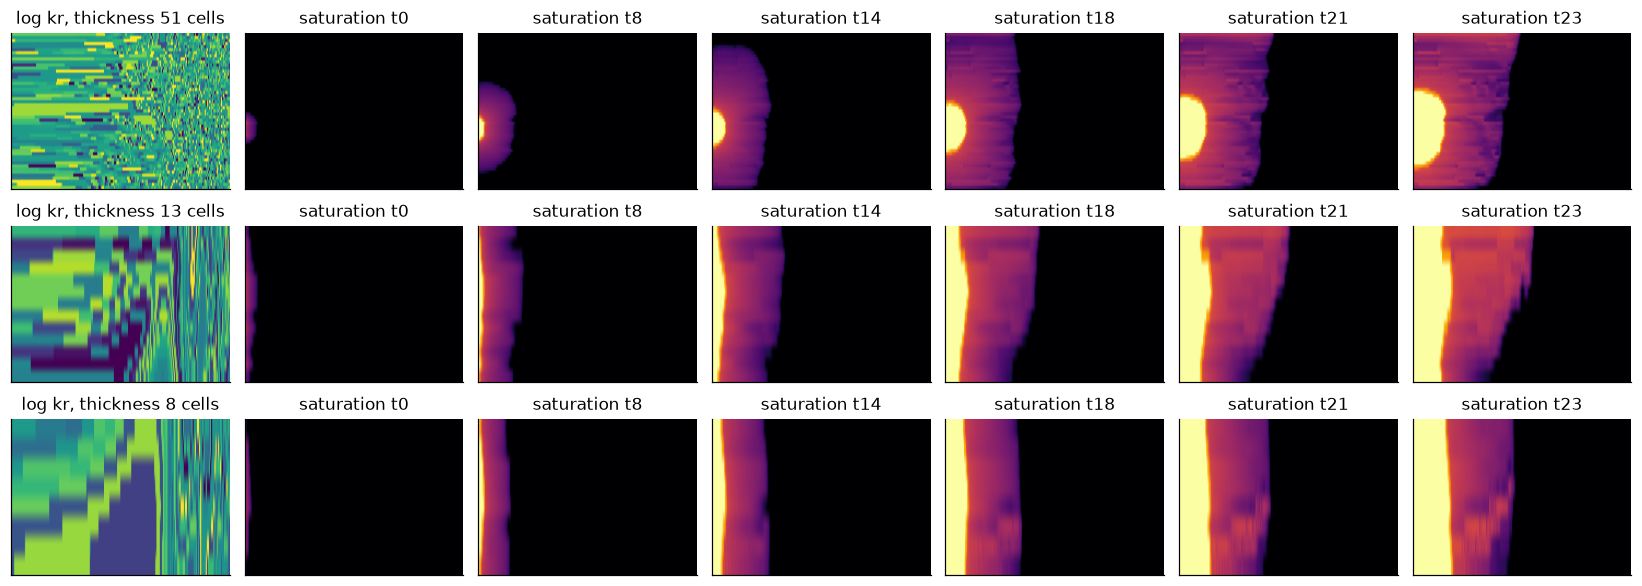

In [2]:
T = [0, 8, 14, 18, 21, 23]
fig, ax = plt.subplots(3, 1 + len(T), figsize=(15, 5.4))
for r, i in enumerate((0, 1, 2)):
    m = act(xtr[i]); th = int(m[:, 0].sum())
    ax[r, 0].imshow(xtr[i, :th, :, 0], aspect="auto", cmap="viridis"); ax[r, 0].set_title(f"log kr, thickness {th} cells")
    for c, t in enumerate(T):
        ax[r, c + 1].imshow(ytr[i, :th, :, t], aspect="auto", cmap="inferno", vmin=0, vmax=1); ax[r, c + 1].set_title(f"saturation t{t}")
for a in ax.flat: a.set_xticks([]); a.set_yticks([])
plt.tight_layout()

## Sparsity over time
The plume grows from a few cells to a large region; early snapshots are almost empty. Relative errors averaged over all 24 snapshots weight the late, large plumes.

output cells that are zero          0.928292
active cells                        0.537375
plume cells among active (all t)    0.133441
dtype: float64

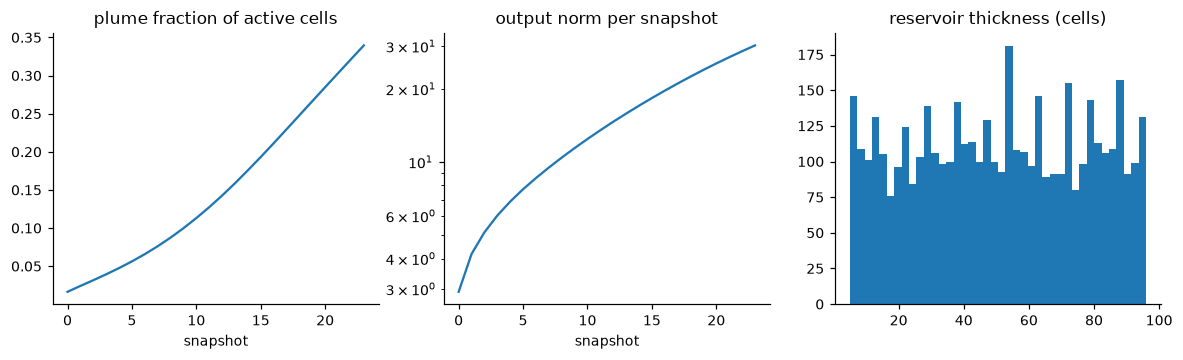

In [3]:
A = act(xtr[:500])[..., None].expand(-1, -1, -1, 24)
plume = (ytr[:500] > 0) & A
frac = plume.float().sum((1, 2)) / A.float().sum((1, 2))
norm_t = (ytr[:500] * A).flatten(1, 2).norm(dim=1)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
ax[0].plot(frac.mean(0)); ax[0].set_title("plume fraction of active cells"); ax[0].set_xlabel("snapshot")
ax[1].semilogy(norm_t.mean(0)); ax[1].set_title("output norm per snapshot"); ax[1].set_xlabel("snapshot")
th = act(xtr)[:, :, 0].sum(1); ax[2].hist(th.numpy(), 40); ax[2].set_title("reservoir thickness (cells)")
pd.Series({"output cells that are zero": float((ytr[:500] == 0).float().mean()), "active cells": float(A.float().mean()),
           "plume cells among active (all t)": float(plume.float().sum() / A.float().sum())})

## Why per-cell normalisation fails here
The per-cell standard deviation over training samples is ~0 wherever plumes rarely reach; dividing by it inflates those cells' targets by orders of magnitude.

cells with std < 1e-4: 71.6%


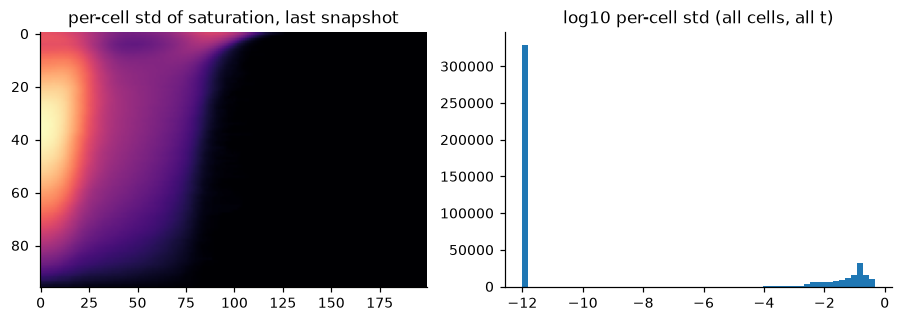

In [4]:
sd = ytr.std(0)                                            # (96, 200, 24)
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].imshow(sd[..., 23], aspect="auto", cmap="magma"); ax[0].set_title("per-cell std of saturation, last snapshot")
ax[1].hist(torch.log10(sd.flatten() + 1e-12).numpy(), 60); ax[1].set_title("log10 per-cell std (all cells, all t)")
print(f"cells with std < 1e-4: {100 * float((sd < 1e-4).float().mean()):.1f}%")

## How hard is the map? Baselines
Masked relative L2 over active cells and all snapshots (the stage-1 training metric), and the plume MAE of Wen et al. (plume = cells non-zero in data or prediction).

In [5]:
def masked_rel(p, x, y):
    m = act(x)[..., None].float(); return rel(p * m, y * m)
def plume_mae(p, x, y, thr=0.0):
    out = []
    for i in range(len(y)):
        m = act(x[i])[..., None].expand_as(y[i]); pl = m & ((y[i] > 0) | (p[i] > thr))
        out.append((p[i] - y[i])[pl].abs().mean())
    return torch.stack(out)
pool = lambda x: torch.nn.functional.avg_pool2d(x.permute(0, 3, 1, 2), 8).flatten(1)
D = torch.cdist(pool(xte[:, :, :, :9]), pool(xtr[:, :, :, :9]))          # reservoir fields + scalars
nn_pred = ytr[D.argmin(1)] * act(xte)[..., None]
mean_pred = ytr.mean(0, keepdim=True).expand_as(yte) * act(xte)[..., None]
pd.DataFrame({"masked rL2 %": {"train mean": 100 * float(masked_rel(mean_pred, xte, yte).mean()),
                               "nearest training sample": 100 * float(masked_rel(nn_pred, xte, yte).mean())},
              "plume MAE": {"train mean": float(plume_mae(mean_pred, xte, yte).mean()),
                            "nearest training sample": float(plume_mae(nn_pred, xte, yte).mean())}})

,masked rL2 %,plume MAE
train mean,54.630411,0.119981
nearest training sample,59.809756,0.188313


## What drives the plume?
Plume size at 30 years against the scalar controls and the reservoir's mean permeability.

In [6]:
size = ((ytr[..., 23] > 0) & act(xtr)).float().sum((1, 2))
feat = {"injection rate": xtr[:, 0, 0, 4], "pressure": xtr[:, 0, 0, 5], "temperature": xtr[:, 0, 0, 6], "Swi": xtr[:, 0, 0, 7],
        "lambda": xtr[:, 0, 0, 8], "thickness": act(xtr)[:, :, 0].sum(1).float(),
        "mean log kr (active)": (xtr[..., 0] * act(xtr)).sum((1, 2)) / act(xtr).sum((1, 2))}
pd.Series({k: float(torch.corrcoef(torch.stack([v.float(), size]))[0, 1]) for k, v in feat.items()}, name="corr with plume size").round(3)

injection rate          0.240
pressure               -0.033
temperature            -0.041
Swi                     0.015
lambda                 -0.031
thickness               0.742
mean log kr (active)   -0.445
Name: corr with plume size, dtype: float64

## Takeaways for training
* **No per-cell normalisation:** many cells have ~0 spread (see above); use the data as given (`--norm none`), as U-FNO does.
* **Mask everything to active cells** (loss, metrics, GP likelihood, calibration), per sample.
* **Time is a dimension, not just channels:** the plume at t is the plume at t−1 grown; a model that shares structure
  across snapshots (3D operator over r, z, t, or an autoregressive-in-time head) uses that; 24 independent output channels do not.
* **Metric:** the plume MAE depends strongly on how a "non-zero prediction" is thresholded; compare methods under one definition.